# 01 · Exploratory Data Analysis (EDA)

**Goal of Day 1:** understand both datasets *before* building any model.
We answer: What columns are there? Is anything missing or broken? How many customers churn?
Which columns seem to be linked to churn?

- **Telco**: 7,043 telecom customers. Target column: `Churn` (Yes/No).
- **Bank**: 10,000 bank customers. Target column: `Exited` (1 = left, 0 = stayed).

Run the data download first: `uv run python scripts/download_data.py`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")       # cleaner default look for all charts
pd.set_option("display.max_columns", None)  # show every column instead of "..."

DATA_DIR = Path("..") / "data" / "raw"  # the notebook runs from notebooks/, so go up one level

## 1. Load the data

In [2]:
telco = pd.read_csv(DATA_DIR / "telco_churn.csv")
bank = pd.read_csv(DATA_DIR / "bank_churn.csv")

print("Telco:", telco.shape)  # (rows, columns)
print("Bank: ", bank.shape)

Telco: (7043, 21)
Bank:  (10000, 14)


In [3]:
telco.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
bank.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2. Column types and missing values

`.info()` shows each column's type. Watch for numbers stored as text (`object`/`str`):
the model can't use those until we convert them.

In [5]:
telco.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
bank.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [7]:
print("Missing values (Telco):", telco.isna().sum().sum())
print("Missing values (Bank): ", bank.isna().sum().sum())

Missing values (Telco): 0
Missing values (Bank):  0


### The hidden problem in Telco: `TotalCharges`

`TotalCharges` should be a number, but pandas read it as text. That happens when *some* rows
contain something that isn't a number. `isna()` said 0 missing, so the bad values must be
blank strings `" "`, which pandas doesn't count as missing.

In [8]:
# errors="coerce": anything that can't become a number turns into NaN (missing)
total_charges = pd.to_numeric(telco["TotalCharges"], errors="coerce")
bad_rows = telco[total_charges.isna()]

print("Rows where TotalCharges is not a number:", len(bad_rows))
bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Rows where TotalCharges is not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


All of these customers have `tenure = 0`: they **just joined** and haven't been billed yet.
So the blank really means "0 so far". On Day 2 our cleaning step will set them to 0.

## 3. How many customers churn? (class balance)

If very few customers churn, a model can get high *accuracy* just by always saying "won't churn".
Knowing this ratio tells us which metrics to trust on Day 3.

Telco churn rate: 26.5%
Bank churn rate:  20.4%


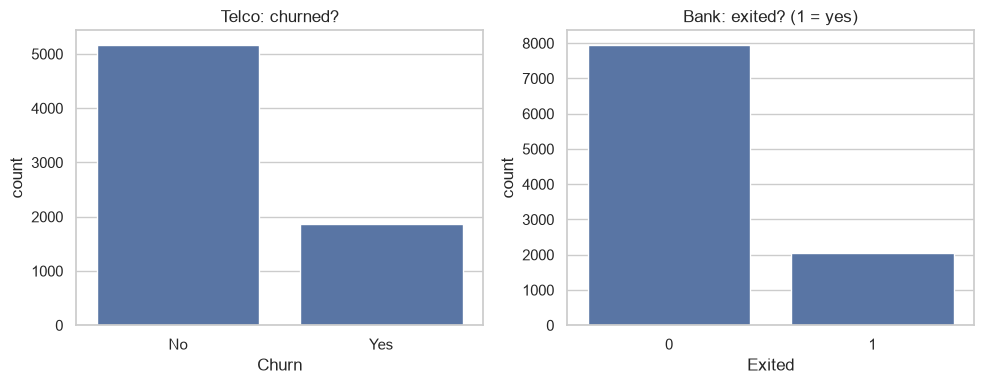

In [9]:
telco_rate = (telco["Churn"] == "Yes").mean()
bank_rate = bank["Exited"].mean()  # Exited is already 0/1, so the mean is the churn rate

print(f"Telco churn rate: {telco_rate:.1%}")
print(f"Bank churn rate:  {bank_rate:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=telco, x="Churn", ax=axes[0]).set_title("Telco: churned?")
sns.countplot(data=bank, x="Exited", ax=axes[1]).set_title("Bank: exited? (1 = yes)")
plt.tight_layout()
plt.show()

## 4. Number columns vs churn

A *box plot* shows the spread of values: the box is the middle 50% of customers, the line in it is
the median. If the boxes for churned vs stayed look very different, that column is useful.

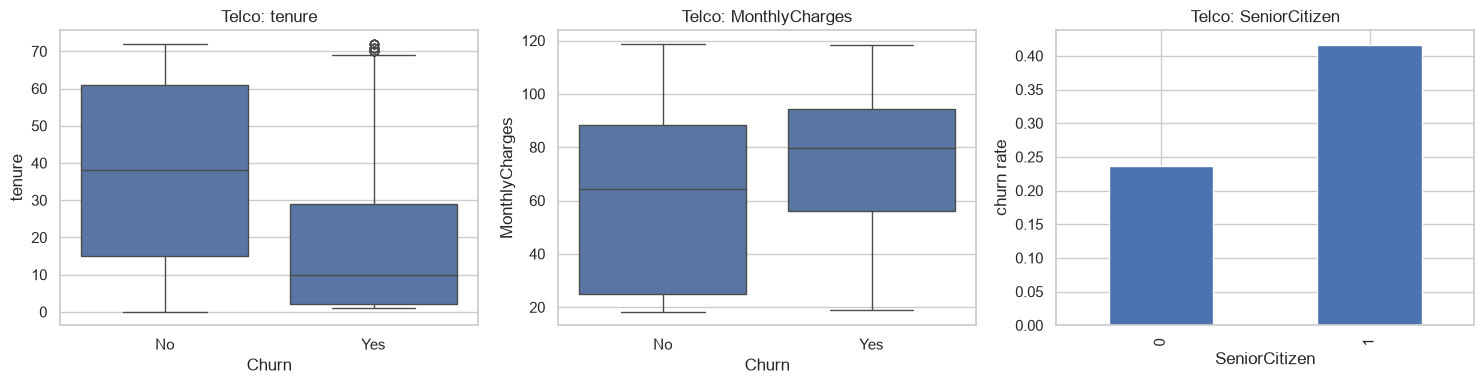

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "SeniorCitizen"]):
    if col == "SeniorCitizen":
        # SeniorCitizen is 0/1, so a churn rate per group is clearer than a box plot
        telco.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()).plot.bar(ax=ax)
        ax.set_ylabel("churn rate")
    else:
        sns.boxplot(data=telco, x="Churn", y=col, ax=ax)
    ax.set_title(f"Telco: {col}")
plt.tight_layout()
plt.show()

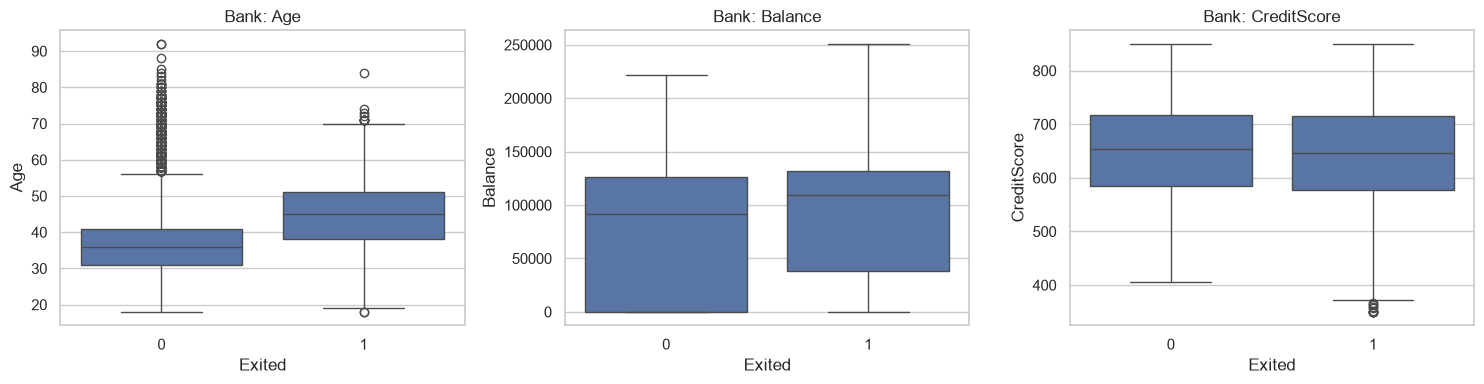

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "Balance", "CreditScore"]):
    sns.boxplot(data=bank, x="Exited", y=col, ax=ax)
    ax.set_title(f"Bank: {col}")
plt.tight_layout()
plt.show()

## 5. Category columns vs churn

For text columns, we compare the **churn rate inside each group**, e.g. "of all customers on a
month-to-month contract, what % left?".

In [12]:
def churn_rate_by(df, col, target, positive):
    """Return the churn rate (and customer count) for each value of `col`."""
    churned = df[target] == positive
    return (
        churned.groupby(df[col])
        .agg(churn_rate="mean", customers="size")
        .sort_values("churn_rate", ascending=False)
    )

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport"]:
    print(churn_rate_by(telco, col, "Churn", "Yes").round(3), "\n")

                churn_rate  customers
Contract                             
Month-to-month       0.427       3875
One year             0.113       1473
Two year             0.028       1695 

                 churn_rate  customers
InternetService                       
Fiber optic           0.419       3096
DSL                   0.190       2421
No                    0.074       1526 

                           churn_rate  customers
PaymentMethod                                   
Electronic check                0.453       2365
Mailed check                    0.191       1612
Bank transfer (automatic)       0.167       1544
Credit card (automatic)         0.152       1522 

                     churn_rate  customers
TechSupport                               
No                        0.416       3473
Yes                       0.152       2044
No internet service       0.074       1526 



In [13]:
for col in ["Geography", "Gender", "NumOfProducts", "IsActiveMember"]:
    print(churn_rate_by(bank, col, "Exited", 1).round(3), "\n")

           churn_rate  customers
Geography                       
Germany         0.324       2509
Spain           0.167       2477
France          0.162       5014 

        churn_rate  customers
Gender                       
Female       0.251       4543
Male         0.165       5457 

               churn_rate  customers
NumOfProducts                       
4                   1.000         60
3                   0.827        266
1                   0.277       5084
2                   0.076       4590 

                churn_rate  customers
IsActiveMember                       
0                    0.269       4849
1                    0.143       5151 



## 6. Columns that must NOT go into the model

Some columns only identify a customer. They carry no real pattern, and a model could
"memorize" them instead of learning anything general.

| Dataset | Drop | Why |
|---|---|---|
| Telco | `customerID` | Just an ID |
| Bank | `RowNumber`, `CustomerId` | Just IDs / row positions |
| Bank | `Surname` | A name, not a behavior. Using it could also be unfair (it can hint at ethnicity) |

In [14]:
print("Unique customerID values:", telco["customerID"].nunique(), "of", len(telco))
print("Unique CustomerId values:", bank["CustomerId"].nunique(), "of", len(bank))
print("Unique Surname values:   ", bank["Surname"].nunique(), "of", len(bank))

Unique customerID values: 7043 of 7043
Unique CustomerId values: 10000 of 10000
Unique Surname values:    2932 of 10000


## 7. Summary: what we learned today (feeds into Day 2)

Fill these in yourself after reading the outputs above. Writing it down is how it sticks.

1. **Telco** `TotalCharges` is text because new customers (`tenure = 0`) have a blank value → convert to number, set blanks to 0.
2. **Churn rates:** Telco ≈ ___ %, Bank ≈ ___ %. Both are *imbalanced* → on Day 3 we look at recall/precision, not just accuracy.
3. **Strongest signals (Telco):** ___
4. **Strongest signals (Bank):** ___
5. **Drop before modeling:** `customerID`; `RowNumber`, `CustomerId`, `Surname`.